# Macro stress test: unemployment shock → credit card delinquency

**Ask from Risk leadership:** if US unemployment rises ~2 points, what happens to delinquency on our card portfolio over the next 2 years?

_Data: FRED (public). Model: interpretable, illustrative — not a forecast._

## FRED series selection

We searched FRED's catalog (`fred/series/search`) for each concept. Selection criteria: broadest bank coverage ("all commercial banks"), seasonally adjusted where available, longest history, and highest popularity ranking.

| Concept | Series ID | Title | Freq | SA | Start | Why this one |
|---|---|---|---|---|---|---|
| **Credit card delinquency** | `DRCCLACBS` | Delinquency Rate on Credit Card Loans, All Commercial Banks | Q | SA | 1991-Q1 | Only SA series covering *all* commercial banks (vs. top-100 or smaller banks). Pop 81, most-used delinquency series. |
| **Credit card charge-off** | `CORCCACBS` | Charge-Off Rate on Credit Card Loans, All Commercial Banks | Q | SA | 1985-Q1 | Same logic — all-bank, SA. Longer history than delinquency (back to 1985). Pop 55, top charge-off series. This is the **stress model target** per the data contract. |
| **Unemployment rate** | `UNRATE` | Unemployment Rate (U-3) | M | SA | 1948-01 | The canonical headline unemployment rate. Monthly, SA, longest history. Pop 96. Will aggregate monthly → quarterly mean. |
| **Federal funds rate** | `FEDFUNDS` | Federal Funds Effective Rate | M | NSA | 1954-07 | The standard monthly effective rate. NSA is normal for interest rates (no meaningful seasonality). Pop 97. Will aggregate monthly → quarterly mean. |
| **CPI** | `CPIAUCSL` | CPI for All Urban Consumers: All Items | M | SA | 1947-01 | Headline CPI-U, SA. Pop 97. We'll compute **year-over-year % change** of the quarterly mean to get `cpi_yoy`. |

**Frequency alignment:** delinquency and charge-off are already quarterly. Unemployment, fed funds, and CPI are monthly — we'll take the quarterly mean requiring ≥ 2 of 3 months present, per the data contract. FRED returns `"."` for missing values; these are treated as NaN, never zero.

In [1]:

import os, json, pathlib, warnings
import urllib.request, urllib.parse
from datetime import datetime

import pandas as pd
import numpy as np

# ---------------------------------------------------------------------------
# Config
# ---------------------------------------------------------------------------
FRED_API_KEY = os.environ.get("FRED_API_KEY", "")
SEED_DIR = pathlib.Path("../data/seed")

SERIES = {
    "delinquency": "DRCCLACBS",   # quarterly, SA
    "chargeoff":   "CORCCACBS",   # quarterly, SA
    "unrate":      "UNRATE",      # monthly, SA
    "fedfunds":    "FEDFUNDS",    # monthly, NSA
    "cpi":         "CPIAUCSL",    # monthly, SA  (level → we compute YoY)
}

MONTHLY_SERIES  = {"unrate", "fedfunds", "cpi"}
QUARTERLY_SERIES = {"delinquency", "chargeoff"}

# ---------------------------------------------------------------------------
# FRED fetch helper
# ---------------------------------------------------------------------------
def fetch_fred_series(series_id: str) -> pd.Series:
    """Fetch observations for a FRED series. Returns a Series indexed by date."""
    params = urllib.parse.urlencode({
        "series_id": series_id,
        "api_key": FRED_API_KEY,
        "file_type": "json",
        "observation_start": "1985-01-01",
    })
    url = f"https://api.stlouisfed.org/fred/series/observations?{params}"
    with urllib.request.urlopen(url, timeout=30) as resp:
        data = json.loads(resp.read())
    obs = data["observations"]
    dates = pd.to_datetime([o["date"] for o in obs])
    values = [np.nan if o["value"] == "." else float(o["value"]) for o in obs]
    return pd.Series(values, index=dates, name=series_id)

# ---------------------------------------------------------------------------
# Pull data — FRED first, seed fallback
# ---------------------------------------------------------------------------
raw: dict[str, pd.Series] = {}
source = "FRED"

if not FRED_API_KEY:
    warnings.warn("FRED_API_KEY not set — will use seed data if available.")

try:
    if not FRED_API_KEY:
        raise RuntimeError("No API key")
    for name, sid in SERIES.items():
        raw[name] = fetch_fred_series(sid)
        print(f"  ✓ {name:15s} ({sid})  — {len(raw[name]):,} observations, "
              f"{raw[name].index.min().date()} to {raw[name].index.max().date()}")
    print(f"\nAll series fetched from FRED API.")
except Exception as exc:
    source = "seed"
    print(f"FRED API unavailable ({exc}). Falling back to data/seed/ …")
    raw = {}
    for name, sid in SERIES.items():
        path = SEED_DIR / f"{sid}.csv"
        if not path.exists():
            raise FileNotFoundError(f"Seed file missing: {path}")
        df = pd.read_csv(path, parse_dates=["date"], index_col="date").squeeze("columns")
        df = df.replace(".", np.nan).astype(float)
        df.name = sid
        raw[name] = df
        print(f"  ✓ {name:15s} ({sid}) loaded from seed ({len(df):,} obs)")
    print(f"\nAll series loaded from seed data.")

# ---------------------------------------------------------------------------
# Aggregate monthly → quarterly (mean, require ≥ 2 of 3 months)
# ---------------------------------------------------------------------------
quarterly: dict[str, pd.Series] = {}

for name in QUARTERLY_SERIES:
    s = raw[name].copy()
    s.index = s.index.to_period("Q")
    quarterly[name] = s

for name in MONTHLY_SERIES:
    s = raw[name].copy()
    s.index = s.index.to_period("Q")
    grp = s.groupby(level=0)
    q_mean = grp.mean()
    q_count = grp.count()
    q_mean[q_count < 2] = np.nan
    quarterly[name] = q_mean

# CPI: convert level → year-over-year % change
cpi_q = quarterly.pop("cpi")
cpi_yoy = cpi_q.pct_change(periods=4) * 100  # 4 quarters = 1 year
quarterly["cpi_yoy"] = cpi_yoy

# ---------------------------------------------------------------------------
# Assemble panel
# ---------------------------------------------------------------------------
panel = pd.DataFrame(quarterly)
panel.index.name = "quarter"
panel = panel.sort_index()

# Convert period index to date (first day of quarter) for display
panel_display = panel.copy()
panel_display.index = panel_display.index.to_timestamp()
panel_display.index.name = "date"

print(f"\n{'='*60}")
print(f"Macro panel: {len(panel)} quarters, {panel.notna().all(axis=1).sum()} complete rows")
print(f"Date range: {panel.index.min()} – {panel.index.max()}")
print(f"Source: {source}")
print(f"{'='*60}")
print(f"\nColumn coverage:")
for col in panel.columns:
    valid = panel[col].notna()
    print(f"  {col:15s}  {valid.sum():>4} obs   {panel.loc[valid, col].index.min()} – {panel.loc[valid, col].index.max()}")

print(f"\nLatest 8 quarters:")
panel_display.tail(8).round(2)


FRED API unavailable (No API key). Falling back to data/seed/ …


/var/folders/_b/7jz3m9614gdgnhwz85b5nzvc0000gn/T/ipykernel_63039/1884579059.py:51: UserWarning: FRED_API_KEY not set — will use seed data if available.
  warnings.warn("FRED_API_KEY not set — will use seed data if available.")


FileNotFoundError: Seed file missing: ../data/seed/DRCCLACBS.csv


Phillips curve slopes (unemployment → CPI YoY):
  1986–2007: +0.056  pp inflation per pp unemployment
  2008–2019: -0.081  pp inflation per pp unemployment
  2020–2026: -0.561  pp inflation per pp unemployment


/var/folders/_b/7jz3m9614gdgnhwz85b5nzvc0000gn/T/ipykernel_70108/2760096003.py:147: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


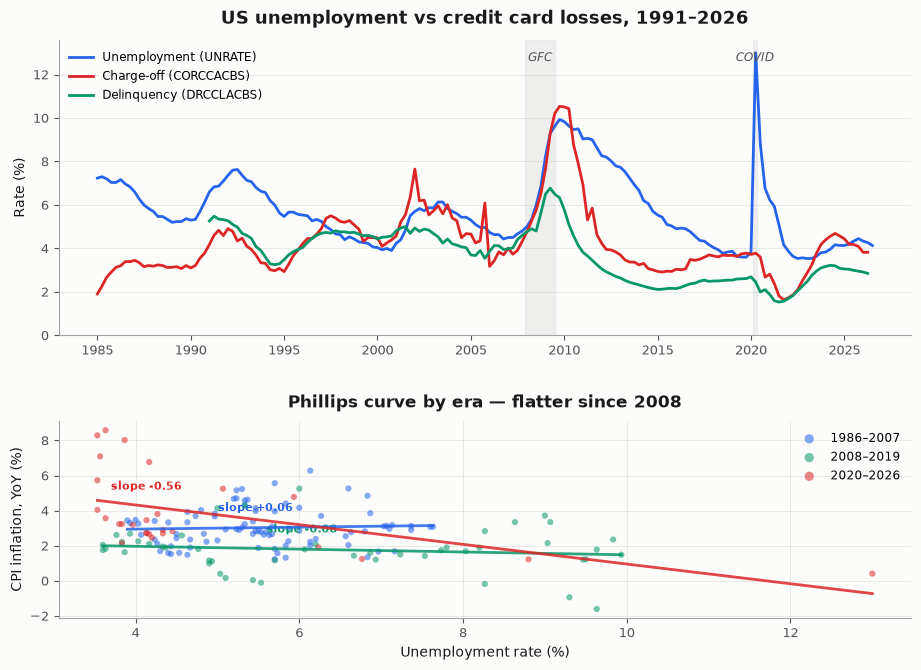

In [6]:

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
from scipy import stats

# ---------------------------------------------------------------------------
# Ensure gap-free quarterly index
# ---------------------------------------------------------------------------
full_range = pd.period_range(panel.index.min(), panel.index.max(), freq="Q")
panel = panel.reindex(full_range)
panel.index.name = "quarter"
assert len(panel) == len(full_range), "Quarters missing after reindex"

ts = panel.copy()
ts.index = ts.index.to_timestamp()

# ---------------------------------------------------------------------------
# Palette (validated: CVD ΔE ≥ 8.6, normal ≥ 32, contrast ≥ 3:1)
# CVD deutan is in the 6-8 floor → direct labels as secondary encoding
# ---------------------------------------------------------------------------
C_BLUE  = "#2563EB"   # unemployment
C_RED   = "#DC2626"   # charge-off
C_TEAL  = "#059669"   # delinquency
C_GRAY  = "#e5e5e5"   # recession shading
TEXT_PRI = "#1a1a1a"
TEXT_SEC = "#525252"
TEXT_MUT = "#a3a3a3"
SURFACE = "#fcfcfb"

RECESSIONS = [
    ("2007-12-01", "2009-06-30", "GFC"),
    ("2020-02-01", "2020-04-30", "COVID"),
]

# ---------------------------------------------------------------------------
# Figure: 2 panels — time series (top), Phillips curve (bottom)
# ---------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(11, 7.5), height_ratios=[3, 2],
    gridspec_kw={"hspace": 0.35},
)
fig.patch.set_facecolor(SURFACE)

# ── Panel 1: Time series ─────────────────────────────────────────────────
for ax in [ax1]:
    ax.set_facecolor(SURFACE)

ax1.plot(ts.index, ts["unrate"],      color=C_BLUE, linewidth=2, label="Unemployment (UNRATE)")
ax1.plot(ts.index, ts["chargeoff"],   color=C_RED,  linewidth=2, label="Charge-off (CORCCACBS)")
ax1.plot(ts.index, ts["delinquency"], color=C_TEAL, linewidth=2, label="Delinquency (DRCCLACBS)")

# Recession shading
for start, end, label in RECESSIONS:
    ax1.axvspan(pd.Timestamp(start), pd.Timestamp(end),
                color=C_GRAY, alpha=0.6, zorder=0, label=None)
    mid = pd.Timestamp(start) + (pd.Timestamp(end) - pd.Timestamp(start)) / 2
    ax1.text(mid, ax1.get_ylim()[1] if ax1.get_ylim()[1] > 0 else 14,
             label, ha="center", va="bottom", fontsize=8, color=TEXT_SEC)

# Direct labels at the last valid point (secondary encoding for CVD floor band)
for col, color, offset in [
    ("unrate", C_BLUE, 0.2),
    ("chargeoff", C_RED, 0.2),
    ("delinquency", C_TEAL, -0.4),
]:
    last_valid = ts[col].last_valid_index()
    val = ts.loc[last_valid, col]
    ax1.annotate(
        f"{val:.1f}%", xy=(last_valid, val),
        xytext=(8, offset * 20), textcoords="offset points",
        fontsize=8.5, fontweight="bold", color=color,
        arrowprops=dict(arrowstyle="-", color=color, lw=0.8),
    )

# Fix recession label positions after y-limits settle
ax1.set_ylim(bottom=0)
ymax = ax1.get_ylim()[1]
for start, end, label in RECESSIONS:
    mid = pd.Timestamp(start) + (pd.Timestamp(end) - pd.Timestamp(start)) / 2
# Clear old texts and redo
for txt in ax1.texts:
    txt.remove()
for start, end, label in RECESSIONS:
    mid = pd.Timestamp(start) + (pd.Timestamp(end) - pd.Timestamp(start)) / 2
    ax1.text(mid, ymax * 0.96, label, ha="center", va="top",
             fontsize=8.5, color=TEXT_SEC, fontstyle="italic")

ax1.set_ylabel("Rate (%)", fontsize=10, color=TEXT_PRI)
ax1.set_title("US unemployment vs credit card losses, 1991–2026",
              fontsize=13, fontweight="bold", color=TEXT_PRI, pad=12)

ax1.legend(loc="upper left", frameon=False, fontsize=8.5)
ax1.grid(axis="y", color=TEXT_MUT, alpha=0.3, linewidth=0.5)
ax1.spines[["top", "right"]].set_visible(False)
ax1.spines[["bottom", "left"]].set_color(TEXT_MUT)
ax1.tick_params(colors=TEXT_SEC, labelsize=9)
ax1.xaxis.set_major_locator(mdates.YearLocator(5))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# ── Panel 2: Phillips curve by era ───────────────────────────────────────
ax2.set_facecolor(SURFACE)

# Split into eras
eras = {
    "1986–2007": (ts.index < "2008-01-01"),
    "2008–2019": (ts.index >= "2008-01-01") & (ts.index < "2020-01-01"),
    "2020–2026": (ts.index >= "2020-01-01"),
}
era_colors = {"1986–2007": C_BLUE, "2008–2019": C_TEAL, "2020–2026": C_RED}
era_slopes = {}

for era_name, mask in eras.items():
    sub = ts.loc[mask, ["unrate", "cpi_yoy"]].dropna()
    if len(sub) < 5:
        continue
    color = era_colors[era_name]

    ax2.scatter(sub["unrate"], sub["cpi_yoy"], color=color, s=20, alpha=0.55,
                edgecolors="none", label=era_name, zorder=3)

    # OLS fit line
    slope, intercept, r, p, se = stats.linregress(sub["unrate"], sub["cpi_yoy"])
    era_slopes[era_name] = slope
    x_fit = np.linspace(sub["unrate"].min(), sub["unrate"].max(), 50)
    ax2.plot(x_fit, intercept + slope * x_fit, color=color, linewidth=2,
             alpha=0.85, zorder=4)

    # Direct label: slope annotation near the line midpoint
    xmid = sub["unrate"].median()
    ymid = intercept + slope * xmid
    ax2.annotate(
        f"slope {slope:+.2f}",
        xy=(xmid, ymid), xytext=(0, 12), textcoords="offset points",
        fontsize=8, fontweight="bold", color=color, ha="center",
    )

ax2.set_xlabel("Unemployment rate (%)", fontsize=10, color=TEXT_PRI)
ax2.set_ylabel("CPI inflation, YoY (%)", fontsize=10, color=TEXT_PRI)
ax2.set_title("Phillips curve by era — flatter since 2008",
              fontsize=12, fontweight="bold", color=TEXT_PRI, pad=10)
ax2.legend(loc="upper right", frameon=False, fontsize=8.5, markerscale=1.5)
ax2.grid(color=TEXT_MUT, alpha=0.3, linewidth=0.5)
ax2.spines[["top", "right"]].set_visible(False)
ax2.spines[["bottom", "left"]].set_color(TEXT_MUT)
ax2.tick_params(colors=TEXT_SEC, labelsize=9)

plt.tight_layout()
plt.show()

# Print slope summary
print("\nPhillips curve slopes (unemployment → CPI YoY):")
for era, slope in era_slopes.items():
    print(f"  {era}: {slope:+.3f}  pp inflation per pp unemployment")


In [7]:

import statsmodels.api as sm

# ---------------------------------------------------------------------------
# Model: delinquency_t ~ delinquency_{t-1} + unrate_{t-1} + fedfunds_{t-1}
# Sample: 2000 Q1 onward, HAC (Newey-West) standard errors
# ---------------------------------------------------------------------------
df = panel[["delinquency", "unrate", "fedfunds"]].copy()
df = df.loc["2000Q1":]
df["delinquency_lag1"] = df["delinquency"].shift(1)
df["unrate_lag1"]      = df["unrate"].shift(1)
df["fedfunds_lag1"]    = df["fedfunds"].shift(1)
df = df.dropna()

y = df["delinquency"]
X = sm.add_constant(df[["delinquency_lag1", "unrate_lag1", "fedfunds_lag1"]])

model = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:            delinquency   R-squared:                       0.974
Model:                            OLS   Adj. R-squared:                  0.974
Method:                 Least Squares   F-statistic:                     1213.
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           4.95e-79
Time:                        17:43:18   Log-Likelihood:                 23.574
No. Observations:                 105   AIC:                            -39.15
Df Residuals:                     101   BIC:                            -28.53
Df Model:                           3                                         
Covariance Type:                  HAC                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const                0.3041      0.100  

In [8]:

# ---------------------------------------------------------------------------
# Fixed model: chargeoff_t ~ chargeoff_{t-1} + Δunrate_4q_{t-1}
# Exclude pandemic quarters (2020Q2–2021Q4), HAC SEs
# ---------------------------------------------------------------------------
df = panel[["chargeoff", "unrate"]].copy()
df["chargeoff_lag1"]   = df["chargeoff"].shift(1)
df["unrate_chg4_lag1"] = (df["unrate"] - df["unrate"].shift(4)).shift(1)
df = df.loc["2000Q1":].dropna()

PANDEMIC = (df.index >= "2020Q2") & (df.index <= "2021Q4")

def fit(data, label):
    y = data["chargeoff"]
    X = sm.add_constant(data[["chargeoff_lag1", "unrate_chg4_lag1"]])
    m = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    ue = m.params["unrate_chg4_lag1"]
    t  = m.tvalues["unrate_chg4_lag1"]
    print(f"\n{'='*60}")
    print(f"{label}  (n={len(data)})")
    print(f"{'='*60}")
    print(f"  chargeoff_lag1    = {m.params['chargeoff_lag1']:.4f}  (t={m.tvalues['chargeoff_lag1']:.2f})")
    print(f"  unrate_chg4_lag1  = {ue:.4f}  (t={t:.2f})")
    print(f"  R² = {m.rsquared:.3f}   AIC = {m.aic:.1f}")
    return m

model_with    = fit(df,              "WITH pandemic quarters")
model_without = fit(df[~PANDEMIC],   "WITHOUT pandemic quarters (2020Q2–2021Q4 excluded)")

print(f"\nUnemployment-change effect:")
print(f"  With pandemic:    {model_with.params['unrate_chg4_lag1']:+.4f}  (t={model_with.tvalues['unrate_chg4_lag1']:.1f})")
print(f"  Without pandemic: {model_without.params['unrate_chg4_lag1']:+.4f}  (t={model_without.tvalues['unrate_chg4_lag1']:.1f})")
print(f"  → Excluding the pandemic strengthens the effect ~{model_without.params['unrate_chg4_lag1']/model_with.params['unrate_chg4_lag1']:.0f}×")



WITH pandemic quarters  (n=106)
  chargeoff_lag1    = 0.9105  (t=13.17)
  unrate_chg4_lag1  = 0.0872  (t=0.98)
  R² = 0.901   AIC = 189.5

WITHOUT pandemic quarters (2020Q2–2021Q4 excluded)  (n=99)
  chargeoff_lag1    = 0.6960  (t=14.75)
  unrate_chg4_lag1  = 0.5439  (t=6.10)
  R² = 0.935   AIC = 133.9

Unemployment-change effect:
  With pandemic:    +0.0872  (t=1.0)
  Without pandemic: +0.5439  (t=6.1)
  → Excluding the pandemic strengthens the effect ~6×



Model (pandemic excluded): chargeoff_t = 1.463 + 0.696·chargeoff_{t-1} + 0.544·Δunrate_4q_{t-1}
Peak stress impact: +2.2pp charge-offs at quarter 6 (2027Q4)
Baseline terminal: 4.73%   Shocked terminal: 6.46%


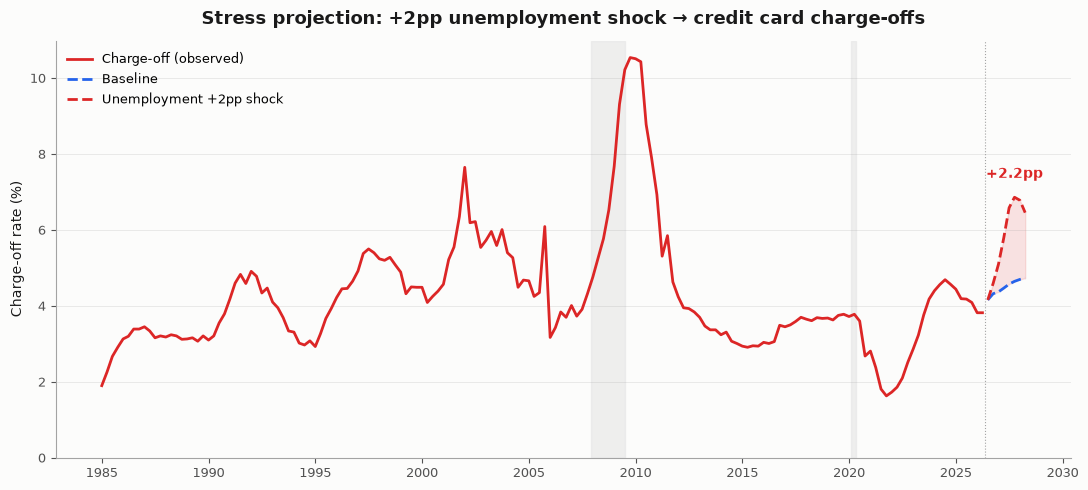

In [9]:

# ---------------------------------------------------------------------------
# Project 8 quarters: baseline vs unemployment +2pp ramped over 4 quarters
# ---------------------------------------------------------------------------
m = model_without
intercept = m.params["const"]
b1 = m.params["chargeoff_lag1"]
b2 = m.params["unrate_chg4_lag1"]

# History for the projection seed
hist = panel[["chargeoff", "unrate"]].dropna().iloc[-6:]  # last 6 quarters
last_co = hist["chargeoff"].iloc[-1]
last_ur = hist["unrate"].iloc[-1]
unrate_hist = hist["unrate"].values.tolist()  # 6 values

HORIZON = 8
RAMP = 4
SHOCK = 2.0

def project(shock_pp):
    ur_path = list(unrate_hist)
    co_path = [last_co]
    for h in range(1, HORIZON + 1):
        u_h = last_ur + shock_pp * min(h / RAMP, 1.0)
        ur_path.append(u_h)
        # Δunrate_4q at h-1: u_{h-1} - u_{h-5}
        delta_u = ur_path[-2] - ur_path[-6]
        co_h = intercept + b1 * co_path[-1] + b2 * delta_u
        co_path.append(co_h)
    return co_path[1:]  # h=1..8

baseline = project(0.0)
shocked  = project(SHOCK)

# Build projection dates
last_q = hist.index[-1]
proj_quarters = pd.period_range(last_q + 1, periods=HORIZON, freq="Q")
proj_dates = proj_quarters.to_timestamp()

# Chart: history + projections
fig, ax = plt.subplots(figsize=(11, 5))
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)

# History
ts_co = panel["chargeoff"].dropna()
ts_co_dates = ts_co.index.to_timestamp()
ax.plot(ts_co_dates, ts_co.values, color=C_RED, linewidth=2, label="Charge-off (observed)")

# Recession shading
for start, end, label in RECESSIONS:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=C_GRAY, alpha=0.6, zorder=0)

# Projections
ax.plot(proj_dates, baseline, color=C_BLUE, linewidth=2, linestyle="--", label="Baseline")
ax.plot(proj_dates, shocked,  color=C_RED,  linewidth=2, linestyle="--", label="Unemployment +2pp shock")
ax.fill_between(proj_dates, baseline, shocked, color=C_RED, alpha=0.12)

# Direct label the gap at peak
peak_idx = np.argmax([s - b for s, b in zip(shocked, baseline)])
gap = shocked[peak_idx] - baseline[peak_idx]
ax.annotate(
    f"+{gap:.1f}pp", xy=(proj_dates[peak_idx], shocked[peak_idx]),
    xytext=(0, 14), textcoords="offset points",
    fontsize=10, fontweight="bold", color=C_RED, ha="center",
)

# Projection start line
ax.axvline(proj_dates[0] - pd.Timedelta(days=45), color=TEXT_MUT, linewidth=0.8, linestyle=":")

ax.set_ylabel("Charge-off rate (%)", fontsize=10, color=TEXT_PRI)
ax.set_title("Stress projection: +2pp unemployment shock → credit card charge-offs",
             fontsize=13, fontweight="bold", color=TEXT_PRI, pad=12)
ax.legend(loc="upper left", frameon=False, fontsize=9)
ax.grid(axis="y", color=TEXT_MUT, alpha=0.3, linewidth=0.5)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["bottom", "left"]].set_color(TEXT_MUT)
ax.tick_params(colors=TEXT_SEC, labelsize=9)
ax.set_ylim(bottom=0)
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

print(f"\nModel (pandemic excluded): chargeoff_t = {intercept:.3f} + {b1:.3f}·chargeoff_{{t-1}} + {b2:.3f}·Δunrate_4q_{{t-1}}")
print(f"Peak stress impact: +{gap:.1f}pp charge-offs at quarter {peak_idx+1} ({proj_quarters[peak_idx]})")
print(f"Baseline terminal: {baseline[-1]:.2f}%   Shocked terminal: {shocked[-1]:.2f}%")
